In [1]:
# Import required libraries

import pandas as pd
import numpy as np

# Libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Regression models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

In [2]:
# Create a sample house price dataset

data = {
    'Area': [
        1200, 1500, 1800, 1000, 2200,
        1400, 1700, 900, 2500, 1300,
        1600, 2000, 1100, 1900, 1450,
        2300, 1250, 1750, 950, 2100,
        1350, 1550, 1850, 1050, 2400,
        1150, 1650, 1950, 850, 2250
    ],

    'Bedrooms': [
        2, 3, 3, 2, 4,
        3, 3, 2, 5, 3,
        3, 4, 2, 4, 3,
        4, 2, 3, 2, 4,
        3, 3, 4, 2, 5,
        2, 3, 4, 2, 4
    ],

    'Bathrooms': [
        2, 2, 3, 1, 3,
        2, 2, 1, 4, 2,
        2, 3, 2, 3, 2,
        3, 3, 2, 1, 3,
        2, 2, 3, 1, 4,
        2, 2, 3, 1, 3
    ],

    'Location': [
        'Delhi', 'Mumbai', 'Delhi', 'Pune', 'Mumbai',
        'Pune', 'Delhi', 'Jaipur', 'Mumbai', 'Pune',
        'Delhi', 'Mumbai', 'Jaipur', 'Delhi', 'Pune',
        'Mumbai', 'Jaipur', 'Delhi', 'Jaipur', 'Mumbai',
        'Pune', 'Delhi', 'Mumbai', 'Jaipur', 'Mumbai',
        'Pune', 'Delhi', 'Mumbai', 'Jaipur', 'Delhi'
    ],

    'Parking': [
        1, 1, 2, 1, 2,
        1, 1, 0, 2, 1,
        1, 2, 0, 2, 1,
        2, 1, 1, 0, 2,
        1, 1, 2, 0, 2,
        1, 1, 2, 0, 2
    ],

    'Property_Age': [
        5, 3, 8, 12, 2,
        7, 4, 15, 1, 6,
        5, 3, 10, 4, 8,
        2, 9, 6, 18, 3,
        7, 5, 2, 14, 1,
        11, 4, 3, 20, 2
    ],

    'Price': [
        65, 85, 105, 48, 135,
        75, 95, 40, 155, 70,
        88, 125, 52, 115, 78,
        145, 60, 98, 42, 130,
        73, 82, 110, 50, 150,
        58, 92, 120, 38, 140
    ]
}

# Convert dictionary into a DataFrame

df = pd.DataFrame(data)

# Display first five rows

df.head()

,Area,Bedrooms,Bathrooms,Location,Parking,Property_Age,Price
0,1200,2,2,Delhi,1,5,65
1,1500,3,2,Mumbai,1,3,85
2,1800,3,3,Delhi,2,8,105
3,1000,2,1,Pune,1,12,48
4,2200,4,3,Mumbai,2,2,135


In [3]:
# Display number of rows and columns

print("Dataset Shape:", df.shape)

# Display column names

print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information

print("\nDataset Information:")
df.info()

Dataset Shape: (30, 7)

Column Names:
['Area', 'Bedrooms', 'Bathrooms', 'Location', 'Parking', 'Property_Age', 'Price']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Area          30 non-null     int64 
 1   Bedrooms      30 non-null     int64 
 2   Bathrooms     30 non-null     int64 
 3   Location      30 non-null     object
 4   Parking       30 non-null     int64 
 5   Property_Age  30 non-null     int64 
 6   Price         30 non-null     int64 
dtypes: int64(6), object(1)
memory usage: 1.8+ KB


In [4]:
# Display statistical summary of numerical columns

df.describe()

,Area,Bedrooms,Bathrooms,Parking,Property_Age,Price
count,30.000000,30.000000,30.00000,30.000000,30.000000,30.000000
mean,1598.333333,3.100000,2.30000,1.200000,6.666667,90.633333
std,476.424060,0.922889,0.83666,0.714384,5.026367,35.451262
min,850.000000,2.000000,1.00000,0.000000,1.000000,38.000000
25%,1212.500000,2.000000,2.00000,1.000000,3.000000,61.250000
50%,1575.000000,3.000000,2.00000,1.000000,5.000000,86.500000
75%,1937.500000,4.000000,3.00000,2.000000,8.750000,118.750000
max,2500.000000,5.000000,4.00000,2.000000,20.000000,155.000000


In [5]:
# Check for missing values in every column

print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Area            0
Bedrooms        0
Bathrooms       0
Location        0
Parking         0
Property_Age    0
Price           0
dtype: int64


In [6]:
# Check the number of duplicate rows

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [7]:
# Remove duplicate rows if any exist

df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (30, 7)


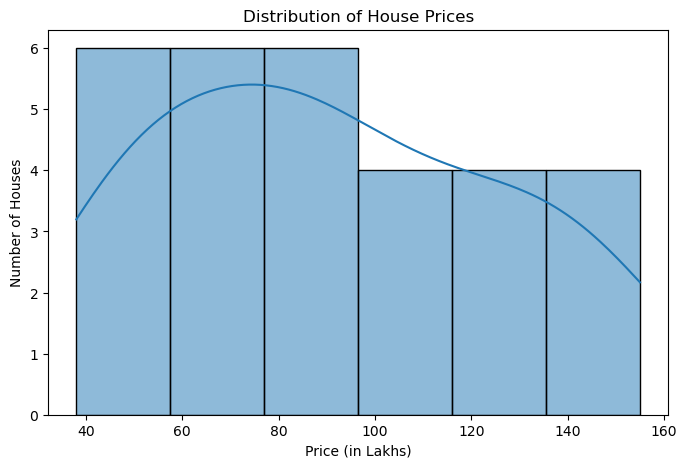

In [8]:
# Plot the distribution of house prices

plt.figure(figsize=(8, 5))

sns.histplot(
    df['Price'],
    kde=True
)

plt.title("Distribution of House Prices")
plt.xlabel("Price (in Lakhs)")
plt.ylabel("Number of Houses")

plt.show()

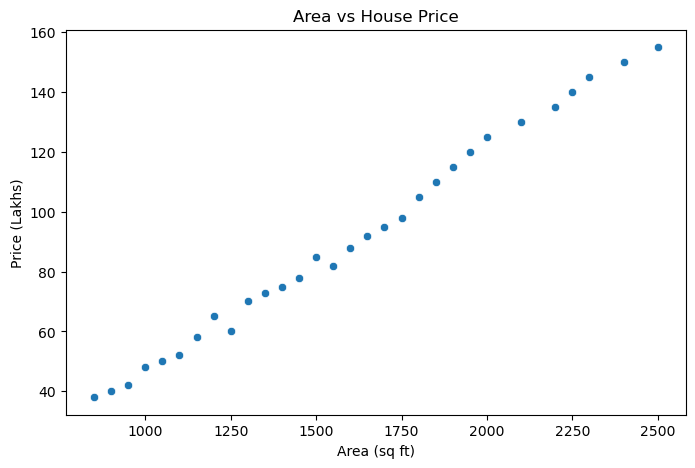

In [9]:
# Visualize the relationship between house area and price

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x='Area',
    y='Price',
    data=df
)

plt.title("Area vs House Price")
plt.xlabel("Area (sq ft)")
plt.ylabel("Price (Lakhs)")

plt.show()

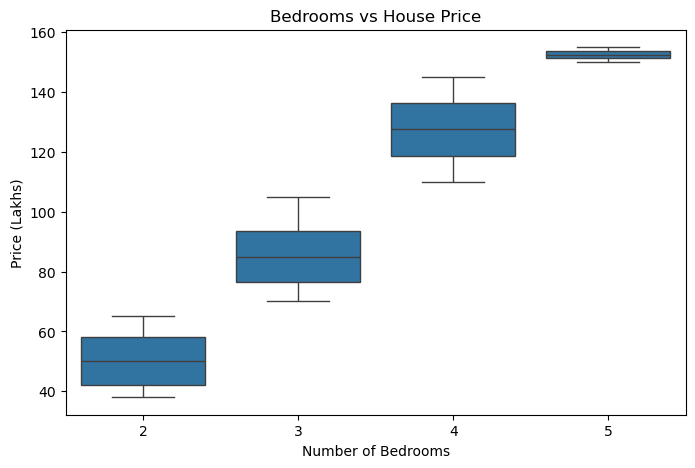

In [10]:
# Visualize the relationship between number of bedrooms
# and house price

plt.figure(figsize=(8, 5))

sns.boxplot(
    x='Bedrooms',
    y='Price',
    data=df
)

plt.title("Bedrooms vs House Price")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Price (Lakhs)")

plt.show()

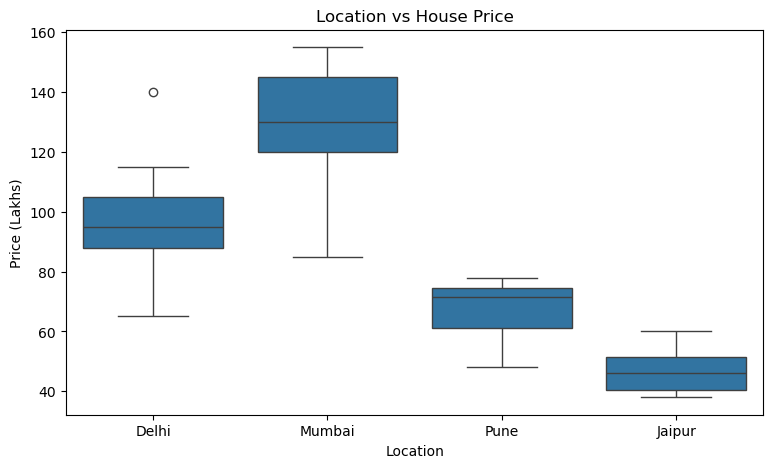

In [11]:
# Compare house prices across different locations

plt.figure(figsize=(9, 5))

sns.boxplot(
    x='Location',
    y='Price',
    data=df
)

plt.title("Location vs House Price")
plt.xlabel("Location")
plt.ylabel("Price (Lakhs)")

plt.show()

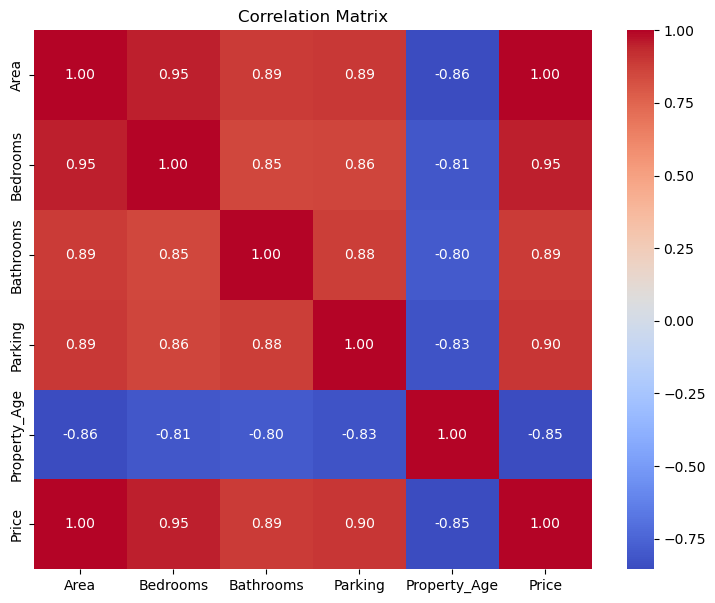

In [12]:
# Select only numerical columns for correlation analysis

numerical_data = df.select_dtypes(
    include=['int64', 'float64']
)

# Calculate correlation matrix

correlation_matrix = numerical_data.corr()

# Visualize correlation matrix

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Matrix")

plt.show()

In [13]:
# Define input features

X = df[
    [
        'Area',
        'Bedrooms',
        'Bathrooms',
        'Location',
        'Parking',
        'Property_Age'
    ]
]

# Define target variable

y = df['Price']

# Display features

print("Input Features:")
print(X.head())

# Display target

print("\nTarget Variable:")
print(y.head())

Input Features:
   Area  Bedrooms  Bathrooms Location  Parking  Property_Age
0  1200         2          2    Delhi        1             5
1  1500         3          2   Mumbai        1             3
2  1800         3          3    Delhi        2             8
3  1000         2          1     Pune        1            12
4  2200         4          3   Mumbai        2             2

Target Variable:
0     65
1     85
2    105
3     48
4    135
Name: Price, dtype: int64


In [14]:
# Split the dataset into training and testing sets
#
# 80% data -> Training
# 20% data -> Testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (24, 6)
Testing data: (6, 6)


In [15]:
# Identify numerical and categorical columns

numerical_features = [
    'Area',
    'Bedrooms',
    'Bathrooms',
    'Parking',
    'Property_Age'
]

categorical_features = [
    'Location'
]

# Create preprocessing pipeline
#
# Numerical columns are standardized using StandardScaler
# Location is converted into numerical values using OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            numerical_features
        ),
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        )
    ]
)

# Apply preprocessing to training data

X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same preprocessing to testing data

X_test_processed = preprocessor.transform(X_test)

print("Data preprocessing completed.")

Data preprocessing completed.


In [16]:
# Create Linear Regression model

linear_model = LinearRegression()

# Train the model

linear_model.fit(
    X_train_processed,
    y_train
)

# Make predictions on test data

linear_predictions = linear_model.predict(
    X_test_processed
)

print("Linear Regression predictions:")
print(linear_predictions)

Linear Regression predictions:
[119.37513188 142.61159768  48.99002742  99.71950263 156.44000454
  68.34092562]


In [17]:
# Calculate Mean Absolute Error

mae_linear = mean_absolute_error(
    y_test,
    linear_predictions
)

# Calculate Mean Squared Error

mse_linear = mean_squared_error(
    y_test,
    linear_predictions
)

# Calculate Root Mean Squared Error

rmse_linear = np.sqrt(mse_linear)

# Calculate R² Score

r2_linear = r2_score(
    y_test,
    linear_predictions
)

print("Linear Regression Performance")
print("--------------------------------")

print("MAE  :", round(mae_linear, 2))
print("MSE  :", round(mse_linear, 2))
print("RMSE :", round(rmse_linear, 2))
print("R²   :", round(r2_linear, 2))

Linear Regression Performance
--------------------------------
MAE  : 1.47
MSE  : 2.48
RMSE : 1.58
R²   : 1.0


In [18]:
# Create Decision Tree Regression model

decision_tree = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

# Train the model

decision_tree.fit(
    X_train_processed,
    y_train
)

# Generate predictions

dt_predictions = decision_tree.predict(
    X_test_processed
)

print("Decision Tree predictions:")
print(dt_predictions)

Decision Tree predictions:
[125. 140.  41.  95. 150.  73.]


In [19]:
# Calculate evaluation metrics

mae_dt = mean_absolute_error(
    y_test,
    dt_predictions
)

mse_dt = mean_squared_error(
    y_test,
    dt_predictions
)

rmse_dt = np.sqrt(mse_dt)

r2_dt = r2_score(
    y_test,
    dt_predictions
)

print("Decision Tree Performance")
print("--------------------------------")

print("MAE  :", round(mae_dt, 2))
print("MSE  :", round(mse_dt, 2))
print("RMSE :", round(rmse_dt, 2))
print("R²   :", round(r2_dt, 2))

Decision Tree Performance
--------------------------------
MAE  : 5.0
MSE  : 29.0
RMSE : 5.39
R²   : 0.98


In [20]:
# Create Random Forest Regression model
#
# Random Forest uses multiple decision trees
# and combines their predictions.

random_forest = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

# Train the Random Forest model

random_forest.fit(
    X_train_processed,
    y_train
)

# Generate predictions

rf_predictions = random_forest.predict(
    X_test_processed
)

print("Random Forest predictions:")
print(rf_predictions)

Random Forest predictions:
[122.45       136.35        44.87        93.51       142.6
  71.02666667]


In [21]:
# Calculate evaluation metrics

mae_rf = mean_absolute_error(
    y_test,
    rf_predictions
)

mse_rf = mean_squared_error(
    y_test,
    rf_predictions
)

rmse_rf = np.sqrt(mse_rf)

r2_rf = r2_score(
    y_test,
    rf_predictions
)

print("Random Forest Performance")
print("--------------------------------")

print("MAE  :", round(mae_rf, 2))
print("MSE  :", round(mse_rf, 2))
print("RMSE :", round(rmse_rf, 2))
print("R²   :", round(r2_rf, 2))

Random Forest Performance
--------------------------------
MAE  : 5.69
MSE  : 47.02
RMSE : 6.86
R²   : 0.97


In [22]:
# Create a DataFrame containing the performance
# of all three regression models

model_comparison = pd.DataFrame({

    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest'
    ],

    'MAE': [
        mae_linear,
        mae_dt,
        mae_rf
    ],

    'MSE': [
        mse_linear,
        mse_dt,
        mse_rf
    ],

    'RMSE': [
        rmse_linear,
        rmse_dt,
        rmse_rf
    ],

    'R2 Score': [
        r2_linear,
        r2_dt,
        r2_rf
    ]
})

# Display model comparison

model_comparison.round(2)

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,1.47,2.48,1.58,1.00
1,Decision Tree,5.00,29.00,5.39,0.98
2,Random Forest,5.69,47.02,6.86,0.97


In [23]:
# Create a DataFrame to compare actual and predicted prices

comparison = pd.DataFrame({

    'Actual Price': y_test.values,

    'Predicted Price': rf_predictions

})

# Display comparison

comparison

,Actual Price,Predicted Price
0,120,122.450000
1,145,136.350000
2,50,44.870000
3,98,93.510000
4,155,142.600000
5,70,71.026667


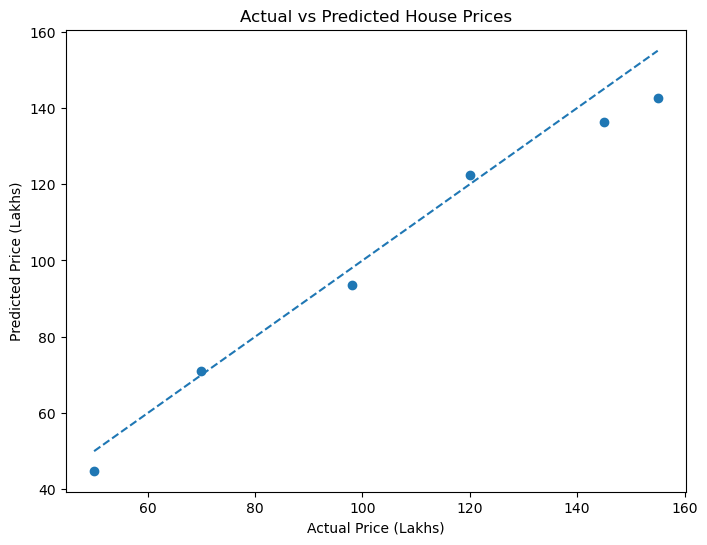

In [24]:
# Plot actual prices against predicted prices

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_predictions
)

# Create a reference line
# Ideally, predictions should be close to this line

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")

plt.title("Actual vs Predicted House Prices")

plt.show()

In [25]:
# Get the feature names after preprocessing

feature_names = preprocessor.get_feature_names_out()

# Get feature importance from Random Forest

importance = random_forest.feature_importances_

# Create DataFrame

feature_importance = pd.DataFrame({

    'Feature': feature_names,

    'Importance': importance

})

# Sort by importance

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display feature importance

feature_importance

,Feature,Importance
0,num__Area,0.571637
3,num__Parking,0.162646
1,num__Bedrooms,0.135387
2,num__Bathrooms,0.070180
4,num__Property_Age,0.050780
6,cat__Location_Jaipur,0.003924
7,cat__Location_Mumbai,0.002486
8,cat__Location_Pune,0.001727
5,cat__Location_Delhi,0.001233


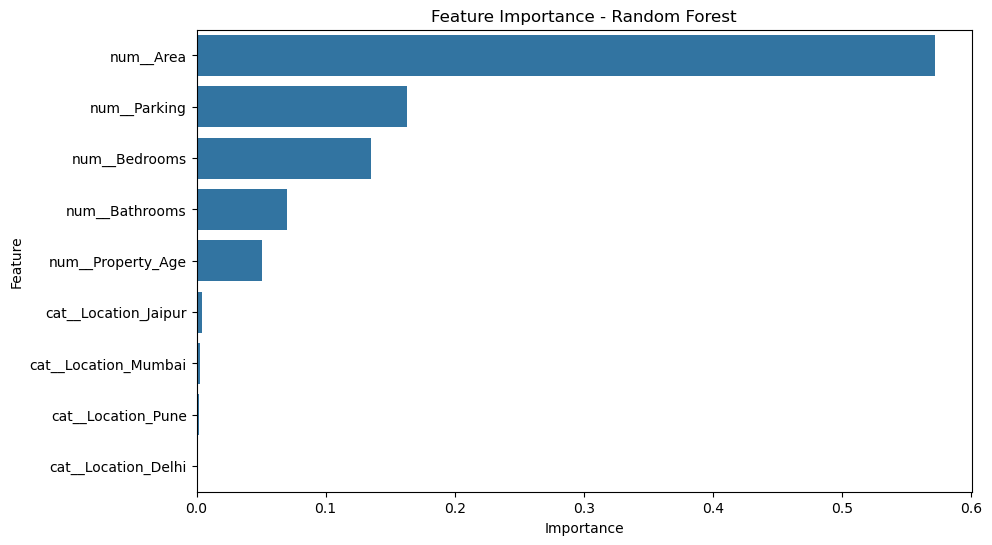

In [26]:
# Visualize feature importance

plt.figure(figsize=(10, 6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_importance
)

plt.title("Feature Importance - Random Forest")

plt.xlabel("Importance")

plt.ylabel("Feature")

plt.show()

In [27]:
# Create information for a new house

new_house = pd.DataFrame({

    'Area': [1800],

    'Bedrooms': [3],

    'Bathrooms': [2],

    'Location': ['Delhi'],

    'Parking': [1],

    'Property_Age': [5]

})

# Display new house information

new_house

,Area,Bedrooms,Bathrooms,Location,Parking,Property_Age
0,1800,3,2,Delhi,1,5


In [28]:
# Apply the SAME preprocessing used during model training

new_house_processed = preprocessor.transform(
    new_house
)

print("New house data has been preprocessed.")

New house data has been preprocessed.


In [29]:
# Predict the price of the new house

predicted_price = random_forest.predict(
    new_house_processed
)

print(
    "Predicted House Price:",
    round(predicted_price[0], 2),
    "Lakhs"
)

Predicted House Price: 96.22 Lakhs


In [30]:
print("House Price Prediction System")
print("--------------------------------")

print("The system predicts house prices using:")

print("1. Area")
print("2. Number of Bedrooms")
print("3. Number of Bathrooms")
print("4. Location")
print("5. Parking Availability")
print("6. Property Age")

print("\nThree regression algorithms were compared:")

print("1. Linear Regression")
print("2. Decision Tree Regression")
print("3. Random Forest Regression")

print("\nModel evaluation was performed using:")

print("MAE, MSE, RMSE and R² Score.")

print("\nThe trained model can predict the estimated")
print("price of a new house based on its features.")

House Price Prediction System
--------------------------------
The system predicts house prices using:
1. Area
2. Number of Bedrooms
3. Number of Bathrooms
4. Location
5. Parking Availability
6. Property Age

Three regression algorithms were compared:
1. Linear Regression
2. Decision Tree Regression
3. Random Forest Regression

Model evaluation was performed using:
MAE, MSE, RMSE and R² Score.

The trained model can predict the estimated
price of a new house based on its features.
